In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Đường dẫn đến thư mục dữ liệu thô (tự động nhận diện local hoặc Google Colab)
RAW = Path("RAW_DATA/raw") if Path("RAW_DATA/raw").exists() else Path("/content/drive/MyDrive/[LTPTDL] Đồ án/raw")

FILES = [
    "Fact", "Calendar", "Business Line", "Group", "Subgroup",
    "Channel", "Region", "Headlines", "KPI", "Ratios"
]

# Đọc toàn bộ bảng dữ liệu dưới dạng chuỗi
tables = {
    f: pd.read_csv(RAW / f"{f}.csv", dtype=str, encoding="utf-8-sig")
    for f in FILES
}

fact = tables["Fact"]

# Kiểm tra kích thước các bảng
{name: df.shape for name, df in tables.items()}

In [ ]:
# Chuẩn bị dữ liệu phục vụ phân tích đa biến
eda = fact.copy()

def parse_amount(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    neg = s.startswith("(") or s.startswith("-")
    s = re.sub(r"USD|\$|[()\s-]", "", s, flags=re.I)
    if re.fullmatch(r"\d{1,3}(?:\.\d{3})+,\d{2}|\d+,\d{2}", s):   # kiểu VN: 6.720,07
        s = s.replace(".", "").replace(",", ".")
    else:                                                          # kiểu quốc tế: 1,632.79
        s = s.replace(",", "")
    return (-1 if neg else 1) * float(s)

eda["Amount_num"] = eda["Amount, $"].map(parse_amount)
group_name = tables["Group"].set_index("Group ID")["Group"]
sg_name = tables["Subgroup"].set_index("Subgroup ID")["Subgroup"]
eda["SG"] = eda["Subgroup ID"].map(sg_name)

print("Đã khởi tạo bản sao dữ liệu 'eda' và chuẩn bị các thông tin danh mục phục vụ phân tích đa biến.")

## 1.2. Phân tích đa biến

### 1.2.1. Phân tích cơ chế dữ liệu thiếu

**a. Chuẩn hóa tạm thời các biến phục vụ phân tích**

In [ ]:
# 1) Parse Date: thử lần lượt 4 định dạng, ô nào chưa parse được thì thử kiểu kế tiếp
eda["Date_parsed"] = pd.to_datetime(eda["Date"], format="%Y-%m-%d", errors="coerce")
for fmt in ["%d/%m/%Y", "%Y%m%d", "%b %d, %Y"]:
    eda["Date_parsed"] = eda["Date_parsed"].fillna(pd.to_datetime(eda["Date"], format=fmt, errors="coerce"))
eda["Month"] = eda["Date_parsed"].dt.month

# 2) Chuẩn hóa nhãn tạm: bỏ khoảng trắng thừa, đưa về chữ thường rồi ánh xạ về nhãn chuẩn
eda["Channel_c"] = eda["Channel"].str.strip().str.lower().map(
    {"online": "Online", "store": "Store", "distributor": "Distributor"})
eda["Region_c"] = eda["Region"].str.strip().str.lower().str.replace("miền ", "", regex=False).map(
    {"bắc": "Bắc", "bac": "Bắc", "trung": "Trung", "nam": "Nam"})
eda["RevExp_c"] = eda["Revenue or expense"].str.strip().str.lower().map(
    {"revenue": "Revenue", "rev": "Revenue", "expense": "Expense", "expenses": "Expense", "exp": "Expense"})

# 3) Nhóm tài chính theo bảng Subgroup
sg2g = tables["Subgroup"].set_index("Subgroup ID")["Group ID"]
eda["Group_SG"] = eda["Subgroup ID"].map(sg2g)
eda["Group_SG_name"] = eda["Group_SG"].map(group_name)

BL = ["Nutrition and Food Supplements", "Sports equipment", "Sportswear"]

**b. Phân tích mối liên hệ giữa dữ liệu thiếu và các biến quan sát được**

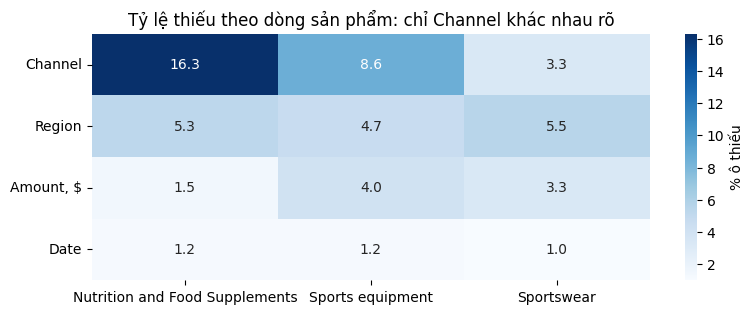

In [ ]:
# Bảng True/False: ô nào đang thiếu ở 4 cột
miss = eda[["Channel", "Region", "Amount, $", "Date"]].isna()

# Tỷ lệ thiếu (%) theo dòng sản phẩm
rate_bl = (miss.groupby(eda["Business Line Name"]).mean() * 100).round(1).reindex(BL)

plt.figure(figsize=(9, 3.2))
sns.heatmap(rate_bl.T, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% ô thiếu"})
plt.xlabel(""); plt.ylabel("")
plt.title("Tỷ lệ thiếu theo dòng sản phẩm: chỉ Channel khác nhau rõ")
plt.xticks(rotation=0); plt.yticks(rotation=0)
plt.show()

In [ ]:
missing_cols = ["Channel", "Region", "Amount, $", "Date"]
factors = {"Dòng sản phẩm": "Business Line Name",
           "Nhóm tài chính": "Group_SG_name",
           "Tháng": "Month"}

results = []
for col in missing_cols:
    for factor_name, factor_col in factors.items():
        # Bảng đếm: số dòng thiếu / không thiếu theo từng nhóm của biến so sánh
        ct = pd.crosstab(eda[factor_col], eda[col].isna())
        if ct.shape[1] < 2:        # Date thiếu thì không có tháng nên cặp Date x Tháng bị bỏ qua
            continue
        chi2, p = chi2_contingency(ct)[:2]
        results.append({
            "Cột thiếu": col,
            "So với": factor_name,
            "Chi-square": round(chi2, 2),
            "p-value": f"{p:.3g}",
            "Kết luận (α = 0,05)": "có liên hệ" if p < 0.05 else "không thấy liên hệ",
        })

missing_tests = pd.DataFrame(results)
missing_tests

,Cột thiếu,So với,Chi-square,p-value,"Kết luận (α = 0,05)"
0,Channel,Dòng sản phẩm,294.33,1.22e-64,có liên hệ
1,Channel,Nhóm tài chính,4.46,0.216,không thấy liên hệ
2,Channel,Tháng,8.72,0.648,không thấy liên hệ
3,Region,Dòng sản phẩm,2.13,0.346,không thấy liên hệ
4,Region,Nhóm tài chính,0.18,0.98,không thấy liên hệ
5,Region,Tháng,16.76,0.115,không thấy liên hệ
6,"Amount, $",Dòng sản phẩm,33.65,4.93e-08,có liên hệ
7,"Amount, $",Nhóm tài chính,29.87,1.47e-06,có liên hệ
8,"Amount, $",Tháng,6.35,0.849,không thấy liên hệ
9,Date,Dòng sản phẩm,1.03,0.597,không thấy liên hệ


**c. Phân tích mối liên hệ giữa thiếu Amount và quy mô khoản mục**

Kiểm định Chi-square đã cho thấy tình trạng thiếu Amount có liên hệ với dòng sản phẩm và nhóm tài chính. Vì vậy, nhóm tiếp tục xem xét liệu quy mô giá trị giao dịch của từng Subgroup có liên quan đến tỷ lệ thiếu Amount hay không.

Cụ thể, nhóm sử dụng trung vị giá trị tuyệt đối của Amount để đại diện cho quy mô giao dịch của từng Subgroup, sau đó tính hệ số tương quan Spearman với tỷ lệ thiếu Amount. Phân tích này giúp xác định xu hướng thiếu dữ liệu theo quy mô khoản mục, nhưng không đủ để kết luận cơ chế MNAR.

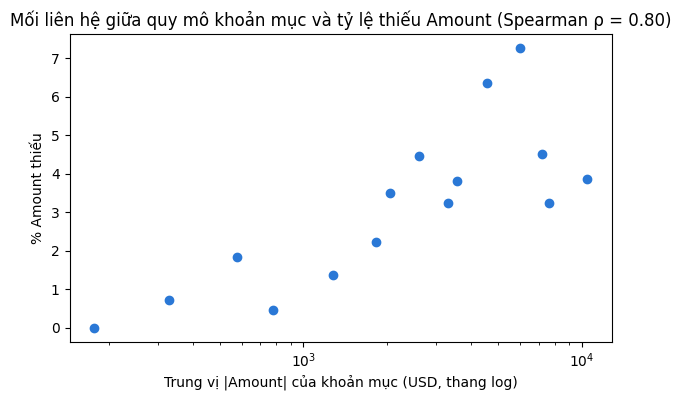

In [ ]:
sg_missing = eda.dropna(subset=["SG"]).groupby("SG").agg(
    Median_Amount=("Amount_num", lambda x: x.abs().median()),
    Missing_Rate=("Amount, $", lambda x: x.isna().mean() * 100),
)
rho, _ = spearmanr(sg_missing["Median_Amount"], sg_missing["Missing_Rate"])

plt.figure(figsize=(7, 4))
plt.scatter(sg_missing["Median_Amount"], sg_missing["Missing_Rate"], color="#2a78d6")
plt.xscale("log")
plt.xlabel("Trung vị |Amount| của khoản mục (USD, thang log)")
plt.ylabel("% Amount thiếu")
plt.title(f"Mối liên hệ giữa quy mô khoản mục và tỷ lệ thiếu Amount (Spearman ρ = {rho:.2f})")
plt.show()

### 1.2.2. Kiểm tra nhất quán giữa các cột

In [ ]:
ok = eda["Group_SG"].notna()          # chỉ xét dòng có Subgroup hợp lệ

# (1) Group ID trong Fact so với nhóm theo bảng Subgroup
grp_bad = ok & (eda["Group ID"] != eda["Group_SG"])

# (2) Nhãn Revenue/Expense so với nhóm
exp_label = np.where(eda["Group_SG"] == "1", "Revenue", "Expense")
re_bad = ok & (eda["RevExp_c"] != exp_label)

# (3) Dấu Amount so với nhóm (Revenue dương, còn lại âm)
valid_amt = ok & eda["Amount_num"].notna() & (eda["Amount_num"] != 0)
exp_sign = np.where(eda["Group_SG"] == "1", 1, -1)
sign_bad = valid_amt & (np.sign(eda["Amount_num"]) != exp_sign)

# (4) Business Line ID so với tên (tên trong bảng danh mục có ký tự \xa0 nên làm sạch trước)
bl_tab = tables["Business Line"].copy()
bl_tab["clean"] = bl_tab["Business Line"].str.replace("\xa0", " ", regex=False).str.strip()
name2id = bl_tab.set_index("clean")["Business Line ID"]
exp_id = eda["Business Line Name"].map(name2id)
bl_valid = eda["Business Line ID"].isin(bl_tab["Business Line ID"])   # ID lạ (như 4) tính riêng ở mục khóa liên kết
bl_bad = bl_valid & (eda["Business Line ID"] != exp_id)

check = pd.DataFrame({"Số dòng": [grp_bad.sum(), re_bad.sum(), sign_bad.sum(), bl_bad.sum()]},
                     index=["Group ID không khớp Subgroup", "Revenue/Expense trái với nhóm",
                            "Dấu Amount trái quy ước", "Business Line ID không khớp tên"])
check["% trên tổng số dòng"] = (check["Số dòng"] / len(eda) * 100).round(2)
check

,Số dòng,% trên tổng số dòng
Group ID không khớp Subgroup,132,1.51
Revenue/Expense trái với nhóm,87,1.00
Dấu Amount trái quy ước,87,1.00
Business Line ID không khớp tên,259,2.97


In [ ]:
cal_days = pd.to_datetime(tables["Calendar"]["Date"])
missing_days = pd.date_range("2023-01-01", "2023-12-31").difference(cal_days)
missing_days.strftime("%d/%m/%Y").tolist()

['27/01/2023', '23/02/2023', '21/06/2023', '20/09/2023', '22/09/2023']